In [25]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("train.csv")
print(df.shape, df["Item_Identifier"].nunique(), df["Outlet_Identifier"].nunique())
df.head()

(8523, 12) 1559 10


,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.20,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,NaN,Tier 3,Grocery Store,732.3800
4,NCD19,8.93,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052


In [26]:
print(df.dtypes)
num = df.select_dtypes(include="number").columns
cat = df.select_dtypes(exclude="number").columns
print("num-", len(num), list(num))
print("cat-", len(cat), list(cat))

Item_Identifier               object
Item_Weight                  float64
Item_Fat_Content              object
Item_Visibility              float64
Item_Type                     object
Item_MRP                     float64
Outlet_Identifier             object
Outlet_Establishment_Year      int64
Outlet_Size                   object
Outlet_Location_Type          object
Outlet_Type                   object
Item_Outlet_Sales            float64
dtype: object
num- 5 ['Item_Weight', 'Item_Visibility', 'Item_MRP', 'Outlet_Establishment_Year', 'Item_Outlet_Sales']
cat- 7 ['Item_Identifier', 'Item_Fat_Content', 'Item_Type', 'Outlet_Identifier', 'Outlet_Size', 'Outlet_Location_Type', 'Outlet_Type']


In [27]:
target = "Item_Outlet_Sales"
feature_cols = ["Item_Weight", "Item_Visibility", "Item_MRP"]
numeric_cols = feature_cols + [target]
cat_cols = ["Item_Fat_Content", "Item_Type", "Outlet_Size", "Outlet_Location_Type",
            "Outlet_Type", "Outlet_Establishment_Year"]
for col in cat_cols:
    print(col, df[col].unique())

Item_Fat_Content ['Low Fat' 'Regular' 'low fat' 'LF' 'reg']
Item_Type ['Dairy' 'Soft Drinks' 'Meat' 'Fruits and Vegetables' 'Household'
 'Baking Goods' 'Snack Foods' 'Frozen Foods' 'Breakfast'
 'Health and Hygiene' 'Hard Drinks' 'Canned' 'Breads' 'Starchy Foods'
 'Others' 'Seafood']
Outlet_Size ['Medium' nan 'High' 'Small']
Outlet_Location_Type ['Tier 1' 'Tier 3' 'Tier 2']
Outlet_Type ['Supermarket Type1' 'Supermarket Type2' 'Grocery Store'
 'Supermarket Type3']
Outlet_Establishment_Year [1999 2009 1998 1987 1985 2002 2007 1997 2004]


In [28]:
df["Item_Fat_Content"] = df["Item_Fat_Content"].str.lower().replace({"lf": "low fat", "reg": "regular"})
print(df["Item_Fat_Content"].value_counts())
df.describe()

Item_Fat_Content
low fat    5517
regular    3006
Name: count, dtype: int64


,Item_Weight,Item_Visibility,Item_MRP,Outlet_Establishment_Year,Item_Outlet_Sales
count,7060.000000,8523.000000,8523.000000,8523.000000,8523.000000
mean,12.857645,0.066132,140.992782,1997.831867,2181.288914
std,4.643456,0.051598,62.275067,8.371760,1706.499616
min,4.555000,0.000000,31.290000,1985.000000,33.290000
25%,8.773750,0.026989,93.826500,1987.000000,834.247400
50%,12.600000,0.053931,143.012800,1999.000000,1794.331000
75%,16.850000,0.094585,185.643700,2004.000000,3101.296400
max,21.350000,0.328391,266.888400,2009.000000,13086.964800


In [29]:
print("vis 0-", (df["Item_Visibility"] == 0).sum())
df.loc[df["Item_Visibility"] == 0, "Item_Visibility"] = np.nan
print("dups-", df.duplicated().sum())
print(df.isnull().sum())
print(df.isnull().sum() / len(df) * 100)

vis 0- 526
dups- 0
Item_Identifier                 0
Item_Weight                  1463
Item_Fat_Content                0
Item_Visibility               526
Item_Type                       0
Item_MRP                        0
Outlet_Identifier               0
Outlet_Establishment_Year       0
Outlet_Size                  2410
Outlet_Location_Type            0
Outlet_Type                     0
Item_Outlet_Sales               0
dtype: int64
Item_Identifier               0.000000
Item_Weight                  17.165317
Item_Fat_Content              0.000000
Item_Visibility               6.171536
Item_Type                     0.000000
Item_MRP                      0.000000
Outlet_Identifier             0.000000
Outlet_Establishment_Year     0.000000
Outlet_Size                  28.276428
Outlet_Location_Type          0.000000
Outlet_Type                   0.000000
Item_Outlet_Sales             0.000000
dtype: float64


In [30]:
print(df.loc[df["Item_Weight"].isnull(), "Outlet_Identifier"].value_counts())
print(df.loc[df["Outlet_Size"].isnull(), "Outlet_Type"].value_counts())
pd.crosstab(df["Outlet_Type"], df["Outlet_Size"])

Outlet_Identifier
OUT027    935
OUT019    528
Name: count, dtype: int64
Outlet_Type
Supermarket Type1    1855
Grocery Store         555
Name: count, dtype: int64


Outlet_Size,High,Medium,Small
Outlet_Type,,,
Grocery Store,0,0,528
Supermarket Type1,932,930,1860
Supermarket Type2,0,928,0
Supermarket Type3,0,935,0


In [31]:
df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].median())
df["Outlet_Size"] = df["Outlet_Size"].fillna("Small")
df.isnull().sum()

Item_Identifier              0
Item_Weight                  0
Item_Fat_Content             0
Item_Visibility              0
Item_Type                    0
Item_MRP                     0
Outlet_Identifier            0
Outlet_Establishment_Year    0
Outlet_Size                  0
Outlet_Location_Type         0
Outlet_Type                  0
Item_Outlet_Sales            0
dtype: int64

In [32]:
print(df["Outlet_Type"].value_counts())
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    out = (df[col] < Q1 - 1.5 * (Q3 - Q1)) | (df[col] > Q3 + 1.5 * (Q3 - Q1))
    sig = ((df[col] - df[col].mean()).abs() > 3 * df[col].std()).sum()
    print(col, "iqr-", out.sum(), "3sig-", sig)
    if out.sum() > 0:
        print(df.loc[out, "Outlet_Type"].value_counts())

Outlet_Type
Supermarket Type1    5577
Grocery Store        1083
Supermarket Type3     935
Supermarket Type2     928
Name: count, dtype: int64
Item_Weight iqr- 0 3sig- 0
Item_Visibility iqr- 173 3sig- 100
Outlet_Type
Grocery Store        167
Supermarket Type1      5
Supermarket Type2      1
Name: count, dtype: int64
Item_MRP iqr- 0 3sig- 0
Item_Outlet_Sales iqr- 186 3sig- 90
Outlet_Type
Supermarket Type3    103
Supermarket Type1     80
Supermarket Type2      3
Name: count, dtype: int64


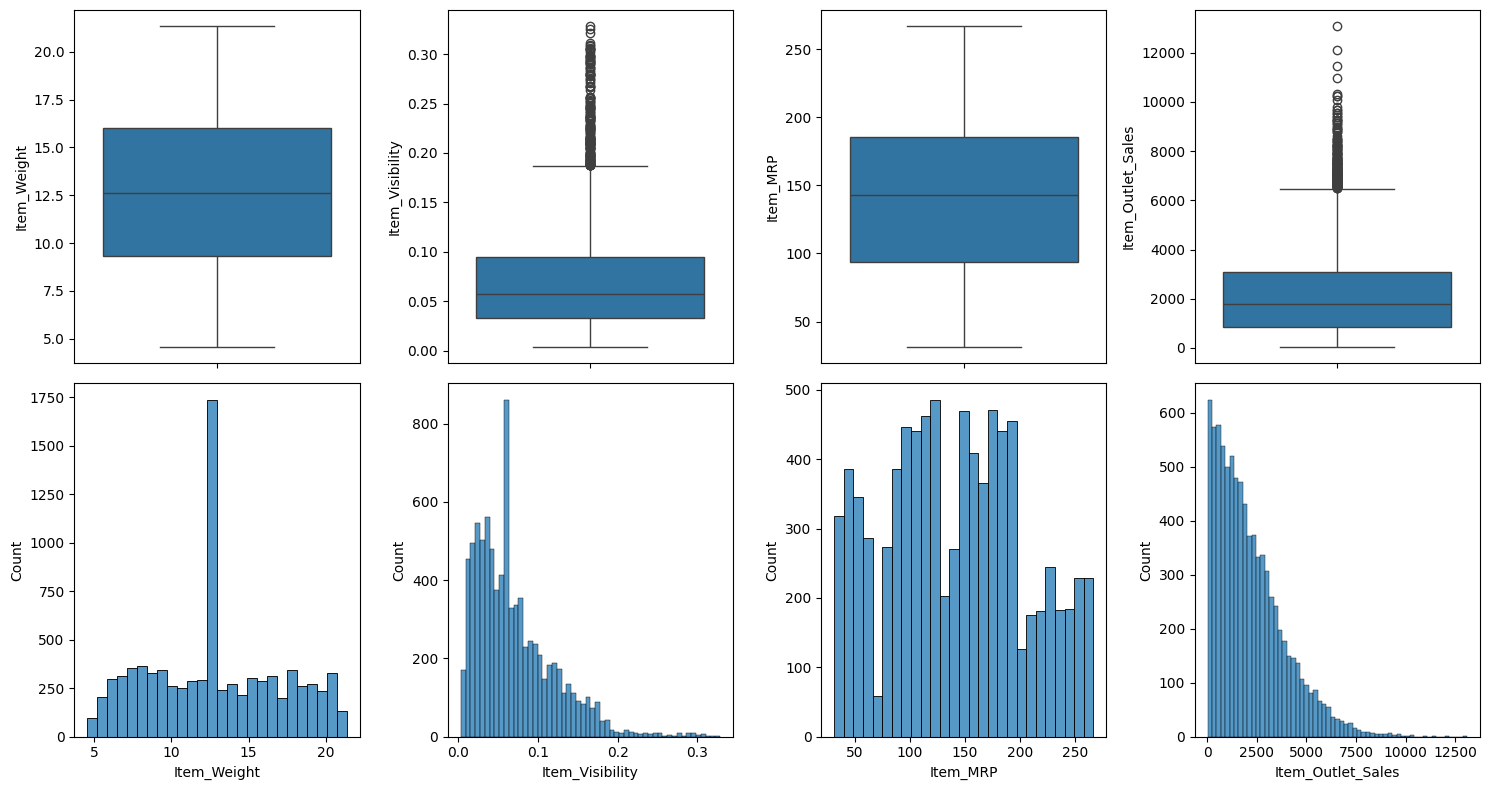

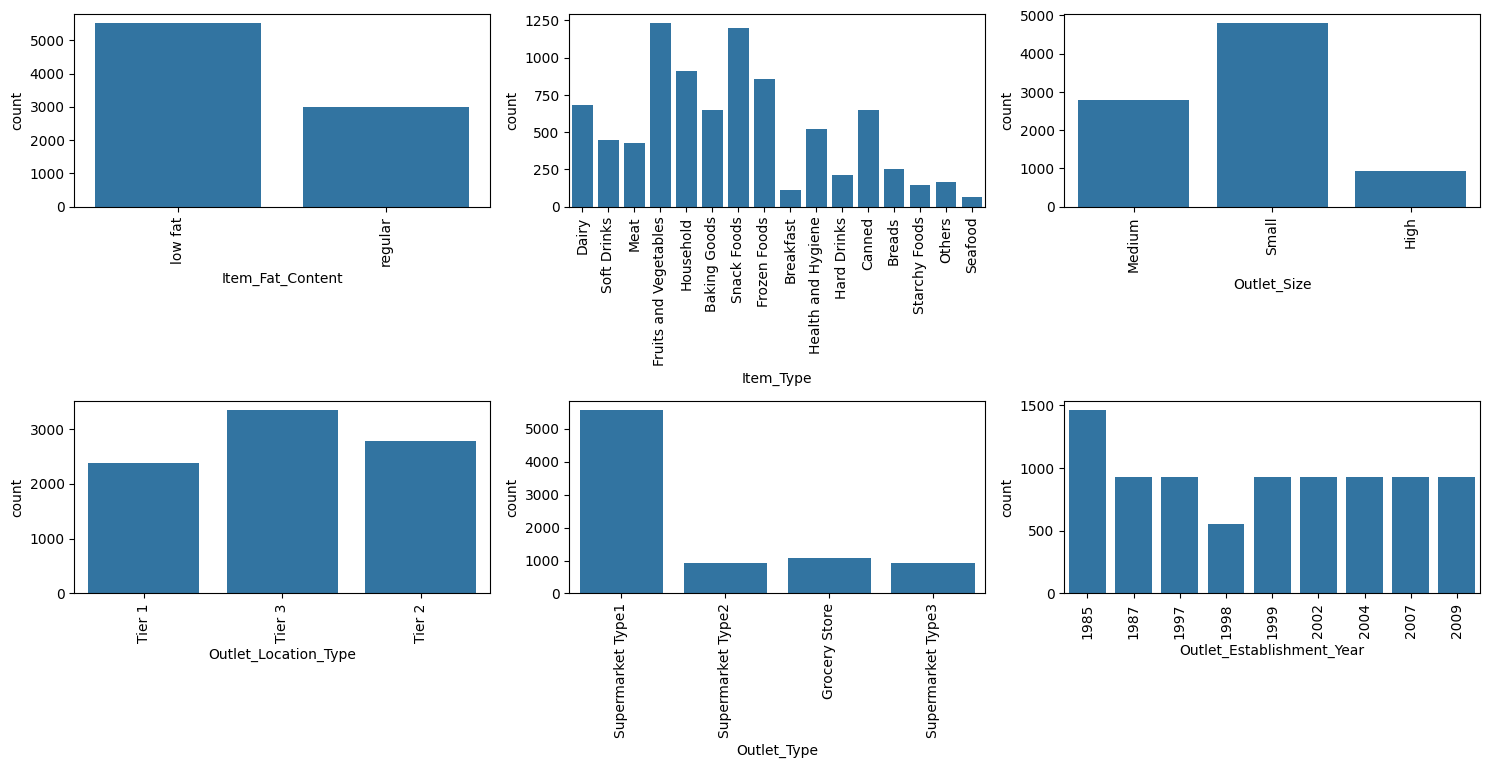

In [33]:
plt.figure(figsize=(15, 8))
for i, col in enumerate(numeric_cols, 1):
    plt.subplot(2, 4, i)
    sns.boxplot(y=df[col])
    plt.subplot(2, 4, i + 4)
    sns.histplot(df[col])
plt.tight_layout()
plt.show()

plt.figure(figsize=(15, 10))
for i, col in enumerate(cat_cols, 1):
    plt.subplot(3, 3, i)
    sns.countplot(x=df[col])
    plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

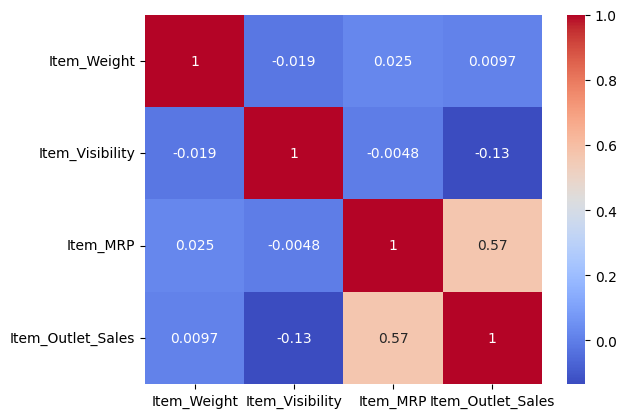

Item_Weight 0.001 vif- 1.0
Item_Visibility 0.0 vif- 1.0
Item_MRP 0.001 vif- 1.0


In [34]:
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap="coolwarm")
plt.show()

from sklearn.linear_model import LinearRegression
for col in feature_cols:
    X = df[feature_cols].drop(columns=[col])
    model = LinearRegression().fit(X, df[col])
    r2 = model.score(X, df[col])
    print(col, round(r2, 3), "vif-", round(1 / (1 - r2), 2))

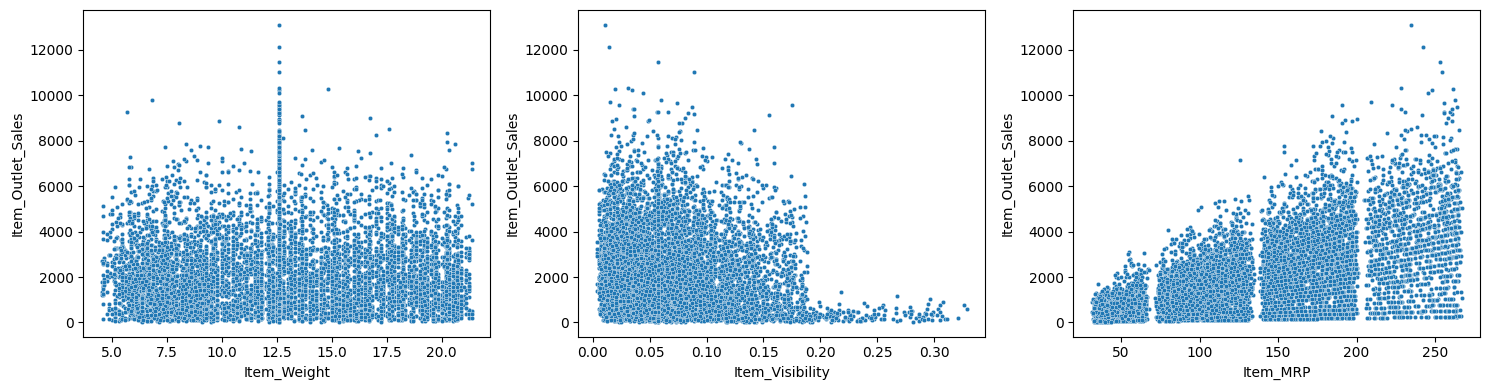

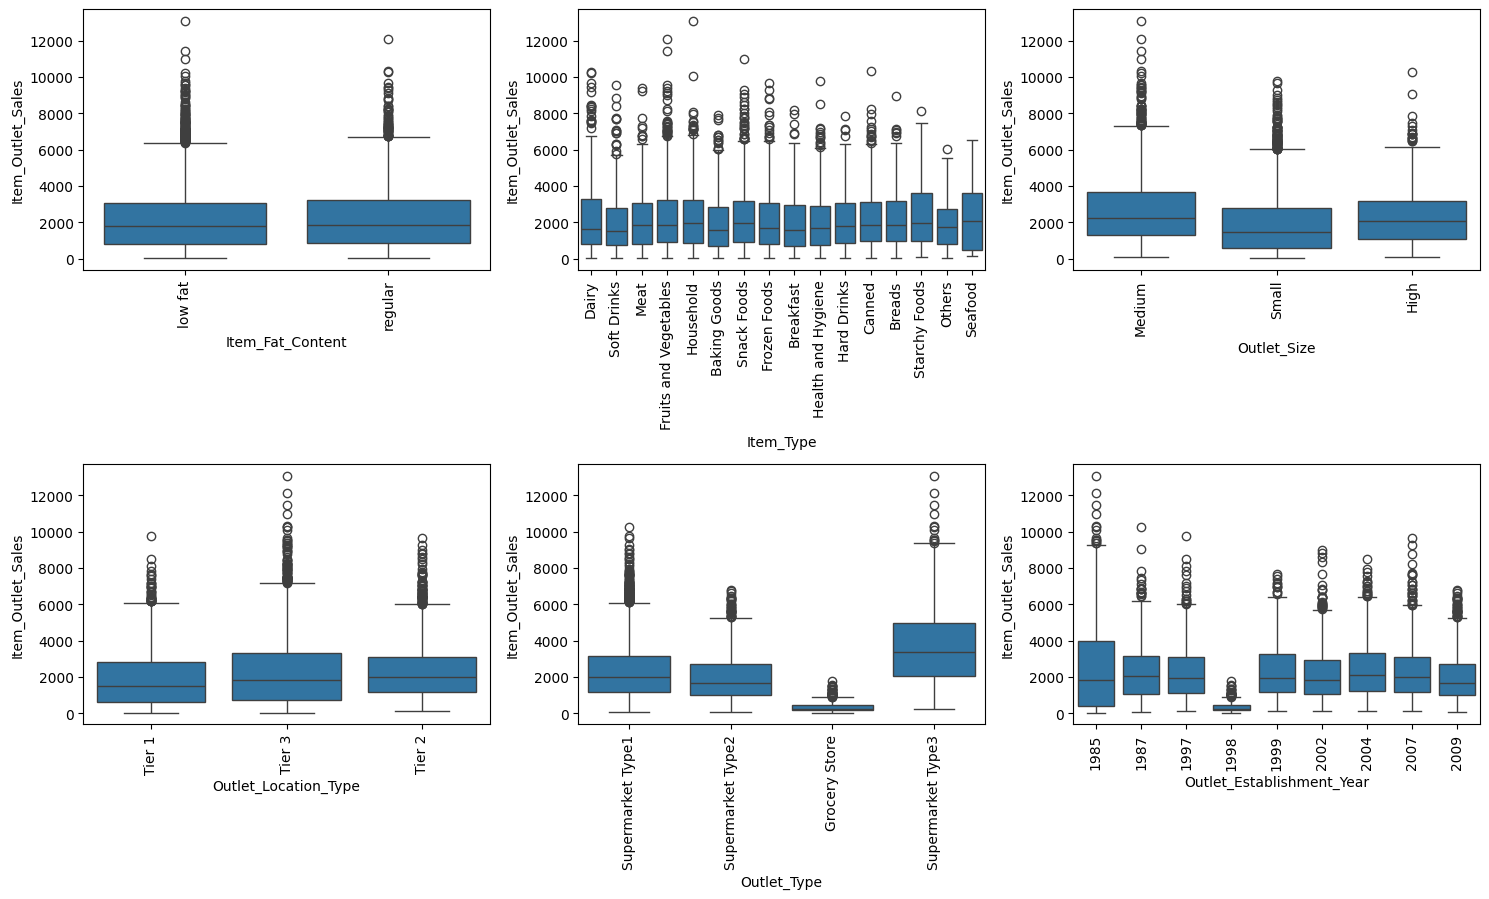

In [35]:
plt.figure(figsize=(15, 4))
for i, col in enumerate(feature_cols, 1):
    plt.subplot(1, 3, i)
    sns.scatterplot(x=df[col], y=df[target], s=10)
plt.tight_layout()
plt.show()

plt.figure(figsize=(15, 12))
for i, col in enumerate(cat_cols, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(x=df[col], y=df[target])
    plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [36]:
for col in cat_cols:
    med = df.groupby(col)[target].median()
    print(med.round(0))
store_cols = ["Outlet_Establishment_Year", "Outlet_Type", "Outlet_Size", "Outlet_Location_Type"]
df.groupby("Outlet_Identifier")[store_cols].first()

Item_Fat_Content
low fat    1765.0
regular    1845.0
Name: Item_Outlet_Sales, dtype: float64
Item_Type
Baking Goods             1578.0
Breads                   1860.0
Breakfast                1555.0
Canned                   1860.0
Dairy                    1651.0
Frozen Foods             1687.0
Fruits and Vegetables    1831.0
Hard Drinks              1817.0
Health and Hygiene       1669.0
Household                1981.0
Meat                     1830.0
Others                   1714.0
Seafood                  2055.0
Snack Foods              1944.0
Soft Drinks              1518.0
Starchy Foods            1968.0
Name: Item_Outlet_Sales, dtype: float64
Outlet_Size
High      2051.0
Medium    2251.0
Small     1484.0
Name: Item_Outlet_Sales, dtype: float64
Outlet_Location_Type
Tier 1    1487.0
Tier 2    2004.0
Tier 3    1812.0
Name: Item_Outlet_Sales, dtype: float64
Outlet_Type
Grocery Store         257.0
Supermarket Type1    1991.0
Supermarket Type2    1655.0
Supermarket Type3    3365.0
Name: 

,Outlet_Establishment_Year,Outlet_Type,Outlet_Size,Outlet_Location_Type
Outlet_Identifier,,,,
OUT010,1998,Grocery Store,Small,Tier 3
OUT013,1987,Supermarket Type1,High,Tier 3
OUT017,2007,Supermarket Type1,Small,Tier 2
OUT018,2009,Supermarket Type2,Medium,Tier 3
OUT019,1985,Grocery Store,Small,Tier 1
OUT027,1985,Supermarket Type3,Medium,Tier 3
OUT035,2004,Supermarket Type1,Small,Tier 2
OUT045,2002,Supermarket Type1,Small,Tier 2
OUT046,1997,Supermarket Type1,Small,Tier 1


In [37]:
df.to_csv("bigmart_clean.csv", index=False)
enc = df.drop(columns=["Item_Identifier", "Outlet_Identifier"])
enc = pd.get_dummies(enc, columns=cat_cols, drop_first=True, dtype=int)
enc.to_csv("bigmart_encoded.csv", index=False)
print(enc.shape)
enc.dtypes.value_counts()

(8523, 35)


int64      31
float64     4
Name: count, dtype: int64